In [13]:
import random
import math
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

random.seed(425)
np.random.seed(425)

os.makedirs("Activity 1/data", exist_ok=True)
os.makedirs("Activity 1/results", exist_ok=True)
os.makedirs("Activity 1/visualizations", exist_ok=True)

users = 5000
items = 100

In [14]:
uniform = []
normal = []
poisson = []

for i in range(users):
    u_row = []
    n_row = []
    p_row = []

    for j in range(items):
        u_row.append(int(random.random() * 5) + 1)

        x = random.random()
        y = random.random()
        z = math.sqrt(-2 * math.log(max(x, 0.000001))) * math.cos(2 * math.pi * y)
        n_row.append(max(1, min(5, round(3 + z))))

        x = random.random()
        k = 0
        probability = math.exp(-2.5)
        total = probability

        while x > total:
            k += 1
            probability = probability * 2.5 / k
            total += probability

        p_row.append(max(1, min(5, k)))

    uniform.append(u_row)
    normal.append(n_row)
    poisson.append(p_row)

uniform = np.array(uniform)
normal = np.array(normal)
poisson = np.array(poisson)

print(uniform.shape)
print(normal.shape)
print(poisson.shape)

(5000, 100)
(5000, 100)
(5000, 100)


In [15]:
mask = np.zeros((users, items), dtype=bool)

for i in range(users):
    selected = random.sample(range(items), 50)
    mask[i, selected] = True

uniform_obs = np.where(mask, uniform, np.nan)
normal_obs = np.where(mask, normal, np.nan)
poisson_obs = np.where(mask, poisson, np.nan)

print("Uniform sparsity:", np.isnan(uniform_obs).mean())
print("Normal sparsity:", np.isnan(normal_obs).mean())
print("Poisson sparsity:", np.isnan(poisson_obs).mean())

Uniform sparsity: 0.5
Normal sparsity: 0.5
Poisson sparsity: 0.5


In [16]:
pd.DataFrame(uniform_obs).to_csv("Activity 1/data/uniform_ratings.csv", index=False)
pd.DataFrame(normal_obs).to_csv("Activity 1/data/normal_ratings.csv", index=False)
pd.DataFrame(poisson_obs).to_csv("Activity 1/data/poisson_ratings.csv", index=False)

print("Datasets saved successfully")

Datasets saved successfully


In [17]:
matrices = {
    "Uniform": uniform_obs,
    "Normal": normal_obs,
    "Poisson": poisson_obs
}

results = []

for name, matrix in matrices.items():
    global_mean = np.nanmean(matrix)
    user_means = np.nanmean(matrix, axis=1)
    mean_of_user_means = np.nanmean(user_means)
    variance = np.nanvar(matrix)
    std = np.nanstd(matrix)
    sparsity = np.isnan(matrix).mean() * 100

    results.append([
        name,
        global_mean,
        mean_of_user_means,
        variance,
        std,
        sparsity
    ])

stats = pd.DataFrame(results, columns=[
    "Distribution",
    "Global Mean",
    "Mean of User Means",
    "Variance",
    "Standard Deviation",
    "Sparsity (%)"
])

print(stats.round(4))
stats.to_csv("Activity 1/results/statistical_metrics.csv", index=False)

  Distribution  Global Mean  Mean of User Means  Variance  Standard Deviation  \
0      Uniform       2.9990              2.9990    1.9961              1.4128   
1       Normal       3.0018              3.0018    1.0175              1.0087   
2      Poisson       2.5185              2.5185    1.7416              1.3197   

   Sparsity (%)  
0          50.0  
1          50.0  
2          50.0  


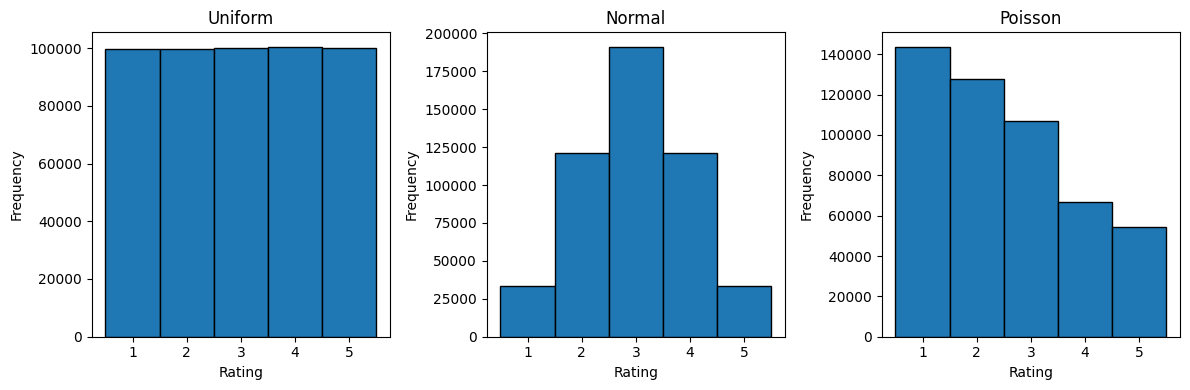

In [18]:
plt.figure(figsize=(12, 4))

for i, (name, matrix) in enumerate({
    "Uniform": uniform,
    "Normal": normal,
    "Poisson": poisson
}.items()):
    plt.subplot(1, 3, i + 1)
    plt.hist(matrix.flatten(), bins=np.arange(0.5, 6.5, 1), edgecolor="black")
    plt.title(name)
    plt.xlabel("Rating")
    plt.ylabel("Frequency")
    plt.xticks(range(1, 6))

plt.tight_layout()
plt.savefig("Activity 1/visualizations/rating_histograms.png")
plt.show()

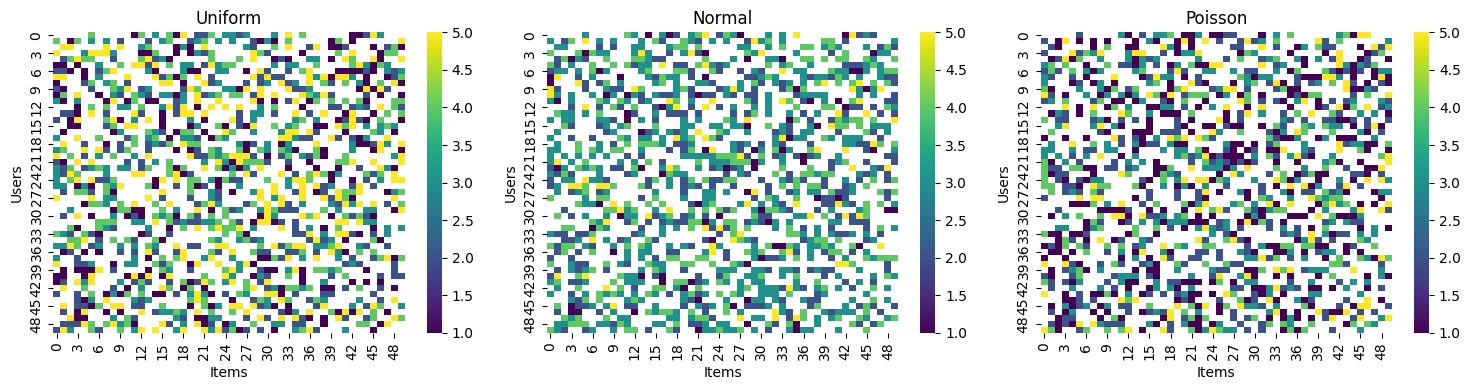

In [19]:
plt.figure(figsize=(15, 4))

for i, (name, matrix) in enumerate(matrices.items()):
    plt.subplot(1, 3, i + 1)
    sns.heatmap(matrix[:50, :50], vmin=1, vmax=5, cmap="viridis")
    plt.title(name)
    plt.xlabel("Items")
    plt.ylabel("Users")

plt.tight_layout()
plt.savefig("Activity 1/visualizations/matrix_heatmaps.png")
plt.show()

In [20]:
complete_matrices = {
    "Uniform": uniform,
    "Normal": normal,
    "Poisson": poisson
}

experiment_results = []

for missing in [0.50, 0.75, 0.90]:
    observed_count = int(items * (1 - missing))

    mask = np.zeros((users, items), dtype=bool)

    for i in range(users):
        selected = random.sample(range(items), observed_count)
        mask[i, selected] = True

    for name, matrix in complete_matrices.items():
        observed = np.where(mask, matrix, np.nan)

        original_mean = matrix.mean()
        observed_mean = np.nanmean(observed)
        error = observed_mean - original_mean

        experiment_results.append([
            name, missing * 100, original_mean, observed_mean, error
        ])

experiment_df = pd.DataFrame(experiment_results, columns=[
    "Distribution", "Missing (%)", "Original Mean",
    "Observed Mean", "Estimation Error"
])

print(experiment_df.round(4))
experiment_df.to_csv("Activity 1/results/missing_data_experiments.csv", index=False)

  Distribution  Missing (%)  Original Mean  Observed Mean  Estimation Error
0      Uniform         50.0         3.0020         3.0003           -0.0017
1       Normal         50.0         2.9998         3.0006            0.0008
2      Poisson         50.0         2.5200         2.5209            0.0008
3      Uniform         75.0         3.0020         2.9988           -0.0032
4       Normal         75.0         2.9998         2.9982           -0.0016
5      Poisson         75.0         2.5200         2.5245            0.0045
6      Uniform         90.0         3.0020         3.0060            0.0040
7       Normal         90.0         2.9998         3.0043            0.0045
8      Poisson         90.0         2.5200         2.5201            0.0001


In [21]:
repeated_results = []

for missing in [0.50, 0.75, 0.90]:
    observed_count = int(items * (1 - missing))

    for repeat in range(100):
        mask = np.zeros((users, items), dtype=bool)

        for i in range(users):
            selected = random.sample(range(items), observed_count)
            mask[i, selected] = True

        for name, matrix in complete_matrices.items():
            observed = np.where(mask, matrix, np.nan)

            error = np.nanmean(observed) - matrix.mean()

            repeated_results.append([
                name, missing * 100, repeat + 1, error
            ])

repeated_df = pd.DataFrame(repeated_results, columns=[
    "Distribution", "Missing (%)", "Repeat", "Error"
])

summary = repeated_df.groupby(["Distribution", "Missing (%)"]).agg(
    Mean_Error=("Error", "mean"),
    Mean_Absolute_Error=("Error", lambda x: np.mean(np.abs(x))),
    Error_Std=("Error", "std")
).reset_index()

print(summary.round(5))
repeated_df.to_csv("Activity 1/results/repeated_experiments.csv", index=False)
summary.to_csv("Activity 1/results/repeated_summary.csv", index=False)

  Distribution  Missing (%)  Mean_Error  Mean_Absolute_Error  Error_Std
0       Normal         50.0     0.00037              0.00117    0.00142
1       Normal         75.0    -0.00033              0.00195    0.00241
2       Normal         90.0    -0.00014              0.00381    0.00460
3      Poisson         50.0     0.00033              0.00142    0.00178
4      Poisson         75.0    -0.00019              0.00295    0.00354
5      Poisson         90.0    -0.00019              0.00465    0.00585
6      Uniform         50.0     0.00030              0.00138    0.00164
7      Uniform         75.0     0.00020              0.00264    0.00342
8      Uniform         90.0    -0.00008              0.00486    0.00610


In [22]:
cold_results = []

for name, matrix in matrices.items():
    old_users, old_items = matrix.shape

    new_matrix = np.full((old_users + 100, old_items + 20), np.nan)
    new_matrix[:old_users, :old_items] = matrix

    for user in range(old_users, old_users + 100):
        selected_items = random.sample(range(old_items + 20), 5)

        for item in selected_items:
            new_matrix[user, item] = random.randint(1, 5)

    old_sparsity = np.isnan(matrix).mean() * 100
    new_sparsity = np.isnan(new_matrix).mean() * 100

    cold_results.append([
        name,
        old_users,
        old_items,
        new_matrix.shape[0],
        new_matrix.shape[1],
        old_sparsity,
        new_sparsity
    ])

cold_df = pd.DataFrame(cold_results, columns=[
    "Distribution",
    "Original Users",
    "Original Items",
    "New Users",
    "New Items",
    "Original Sparsity (%)",
    "New Sparsity (%)"
])

print(cold_df.round(2))
cold_df.to_csv("Activity 1/results/cold_start_results.csv", index=False)

  Distribution  Original Users  Original Items  New Users  New Items  \
0      Uniform            5000             100       5100        120   
1       Normal            5000             100       5100        120   
2      Poisson            5000             100       5100        120   

   Original Sparsity (%)  New Sparsity (%)  
0                   50.0             59.07  
1                   50.0             59.07  
2                   50.0             59.07  


In [23]:
for name, matrix in matrices.items():
    user1 = matrix[0]
    user2 = matrix[1]

    common = ~np.isnan(user1) & ~np.isnan(user2)

    ratings1 = user1[common]
    ratings2 = user2[common]

    print("\n", name)
    print("Co-rated items:", len(ratings1))

    if len(ratings1) >= 2 and np.std(ratings1) > 0 and np.std(ratings2) > 0:
        similarity = np.corrcoef(ratings1, ratings2)[0, 1]
        print("Pearson similarity:", round(similarity, 4))
    else:
        print("Pearson similarity cannot be calculated reliably")


 Uniform
Co-rated items: 23
Pearson similarity: 0.16

 Normal
Co-rated items: 23
Pearson similarity: -0.1867

 Poisson
Co-rated items: 23
Pearson similarity: -0.0617


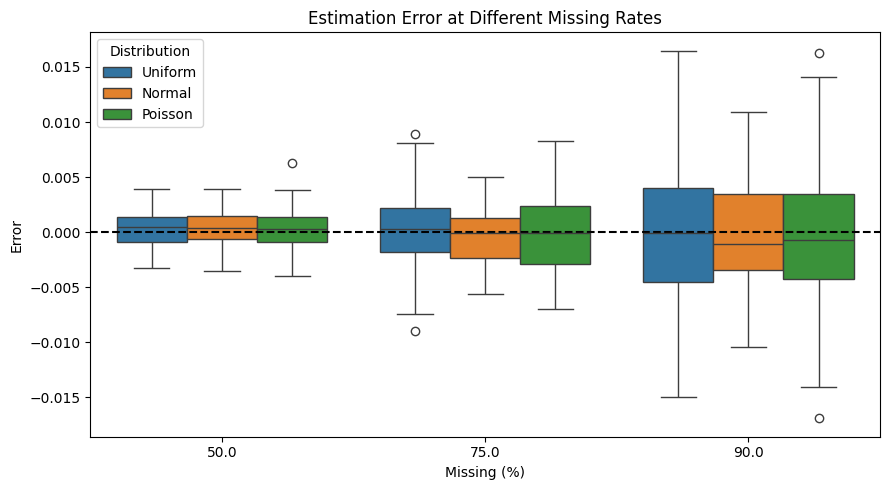

In [24]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=repeated_df,
    x="Missing (%)",
    y="Error",
    hue="Distribution"
)

plt.axhline(0, color="black", linestyle="--")
plt.title("Estimation Error at Different Missing Rates")
plt.tight_layout()
plt.savefig("Activity 1/visualizations/missing_data_analysis.png")
plt.show()